# Scaling study of a methane ground-state calculation

This notebook shows how to use `octopus-profiling` to find how a calculation scales with the number of cores, and which way of parallelizing it is the fastest for each number of cores. It:

1. generates one experiment for each valid parallel layout of the calculation on 1 to 4 cores,
2. runs the experiments one after the other,
3. parses the profiling data written by Octopus,
4. selects the fastest layout for each number of cores,
5. plots the scaling of the total run time.

Octopus and `mpirun` must be found in the `PATH` when the experiments are run, or be made available through the `preamble` of the manager (see below).

> **Note:** the outputs of this notebook come from a single run of a small system on a desktop computer. They illustrate how to use `octopus-profiling`, and the performance numbers might not reflect the actual performance of Octopus, which depends on the system being simulated, the hardware, the compilers and libraries Octopus was built with, and how it was run.

In [1]:
from pathlib import Path

from access.config.parallel_allocation_strategies import RootAllocation
from access.config.parallel_layouts import iter_layouts
from access.profiling import ExistingDirectoryControlSource, RegionGroup
from access.profiling.metrics import tavg

from octopus_profiling import OctopusApplication, OctopusManager

## The calculation

The control calculation is the ground state of methane, with the input file found in the `methane` directory. Its parallelization in states is bounded by the number of states: 4 occupied states for the 8 valence electrons, plus the 4 extra states requested with `ExtraStates`. This is the number Octopus writes as `nst` in `restart/gs/states`.

In [2]:
app = OctopusApplication(name="methane", n_states=8)

## The manager

The manager creates the experiments in `experiments` as copies of the control directory, and archives them in `archive`. The `preamble` holds shell commands run before Octopus in each experiment, e.g. to load environment modules:

```python
preamble = """
module use /path/to/modules
module load Octopus
"""
```

Here Octopus is already in the `PATH`, so no preamble is needed.

In [3]:
manager = OctopusManager(
    Path("experiments"),
    Path("archive"),
    app,
    ExistingDirectoryControlSource(Path("methane").resolve()),
    preamble="",
)

## Parallel layouts

Each layout is one way of distributing the cores among domains, states and k-points, i.e. of setting `ParDomains`, `ParStates` and `ParKPoints`. Only MPI processes are used here, without OpenMP threads, and a "node" is a single core so that the study goes from 1 to 4 cores.

In [4]:
strategy = RootAllocation(thread_range=(1, 1))
num_nodes_list = [1, 2, 3, 4]
cores_per_node = 1

for num_nodes in num_nodes_list:
    layouts = list(iter_layouts(app.parallel_component, num_nodes * cores_per_node, allocations=strategy))
    grids = [layout.decomposition.grid.shape for layout in layouts]
    print(f"{num_nodes} cores: {len(layouts)} layouts (domains, states, k-points): {grids}")

1 cores: 1 layouts (domains, states, k-points): [(1, 1, 1)]
2 cores: 2 layouts (domains, states, k-points): [(1, 2, 1), (2, 1, 1)]
3 cores: 2 layouts (domains, states, k-points): [(1, 3, 1), (3, 1, 1)]
4 cores: 3 layouts (domains, states, k-points): [(1, 4, 1), (2, 2, 1), (4, 1, 1)]


## Running the experiments

`run_experiments` blocks until all experiments are done. Each experiment directory also holds a `run.sh` script, which can be run by hand.

In [5]:
manager.generate_scaling_experiments(
    num_nodes_list=num_nodes_list, cores_per_node=cores_per_node, walltime=1, allocations=strategy
)
manager.run_experiments()
manager.parse_profiling_data()

## Results

The fastest layout for each number of cores is the one with the shortest total run time, i.e. the `COMPLETE_RUN` region of the flat profile. Failed experiments are ignored.

In [6]:
best_experiments = manager.select_best_experiments("time", "COMPLETE_RUN", tavg)
best_experiments

['octopus-layout_methane_dom1_st1_kp1_omp1',
 'octopus-layout_methane_dom2_st1_kp1_omp1',
 'octopus-layout_methane_dom3_st1_kp1_omp1',
 'octopus-layout_methane_dom4_st1_kp1_omp1']

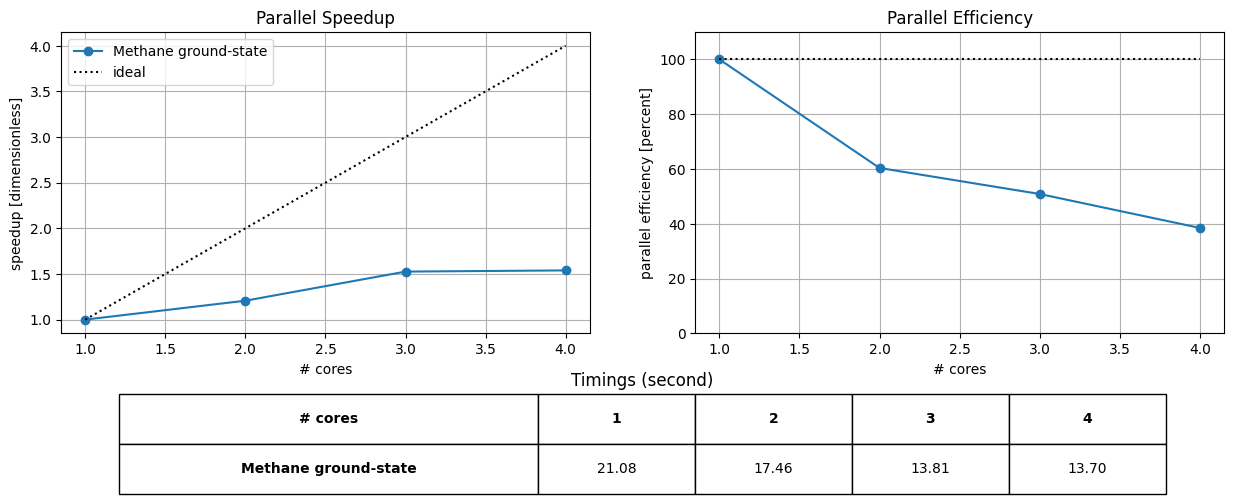

In [7]:
fig = manager.plot_scaling_data(
    [RegionGroup("time", ["COMPLETE_RUN"], relabel={"COMPLETE_RUN": "Methane ground-state"})],
    tavg,
    experiments=best_experiments,
    xlabel="# cores",
)

## Archiving the experiments

Finished experiments can be archived as tarballs in the archive directory, leaving out the `restart` directories written by Octopus. The experiment directories are not deleted, but a manager created later with the same archive directory finds the archived experiments, and parses their data directly from the tarballs.

In [8]:
manager.archive_experiments()
sorted(path.name for path in manager.archive_dir.iterdir())

['octopus-layout_methane_dom1_st1_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom1_st2_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom1_st3_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom1_st4_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom2_st1_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom2_st2_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom3_st1_kp1_omp1.tar.gz',
 'octopus-layout_methane_dom4_st1_kp1_omp1.tar.gz']